# NILM pipeline — train, đánh giá, export weights

**Pipeline đã chốt**
- 6 thiết bị: Fridge, WashMach, Dishwash, Microwave, Toaster, Kettle (TV / HiFi / Fan → "Other").
- **Detector** (Conv1d + BiGRU) → P(ON). **Regressor** (NILMFormer) → công suất "nếu đang ON" (loss chỉ ở bước ON).
- Train **cùng lúc + chặn gradient**: detector học `BCE + λ·phản biện(P(ON) × stopgrad(công suất), thực tế)`, λ = 5; phản biện không chảy vào regressor.
- Suy luận: P(ON) = trung bình các detector, công suất = trung vị các regressor, **mặt nạ mềm** `P(ON) × công suất`, Other = tổng − các thiết bị.

**Quy trình**
1. Chia theo thời gian: train | 1 ngày đệm | val (15% cuối trước test) | test (20% cuối).
2. **Giai đoạn A** — train trên train, dừng sớm trên **val** → số epoch tốt nhất mỗi seed.
3. **Giai đoạn B** — train lại trên **toàn bộ dữ liệu trước test** với số epoch cố định (trung vị của A) → model production.
4. Đánh giá **test một lần** (bảng kWh).
5. Export **weights + config** (không pickle class) → app dựng lại bằng code trong `model/`.

> Chạy notebook với thư mục làm việc là `dataset/training`.

In [23]:
import copy
import sys
from dataclasses import asdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import clear_output

import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

TRAINING_DIR = Path.cwd().resolve()                     # dataset/training
assert (TRAINING_DIR / "model").is_dir(), "Mở notebook với cwd = dataset/training"
DATASET_DIR = TRAINING_DIR.parent
if str(DATASET_DIR) not in sys.path:                    # phải đứng TRƯỚC import training.model
    sys.path.insert(0, str(DATASET_DIR))

from training.model.GRUDetector import GRUConfig, GRUDetector
from training.model.NILMFormerRegressor import NILMFormerConfig, NILMFormerRegressor

DATA_FILE = TRAINING_DIR / "data" / "refit_house2_windows.npz"
CKPT_DIR  = TRAINING_DIR / "checkpoints"
CKPT_DIR.mkdir(exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"torch {torch.__version__} | device: {DEVICE}")

torch 2.15.0+cu132 | device: cuda


## 1. Dữ liệu

In [24]:
with np.load(DATA_FILE) as z:
    aggregate       = z["aggregate"]                                # (N, L)     W
    time_features   = z["time_features"]                            # (N, 8, L)  sin/cos phút, giờ, thứ, tháng
    targets         = z["targets"]                                  # (N, 9, L)  W, cả 9 kênh Appliance
    window_start    = pd.to_datetime(z["window_start"])             # (N,)
    appliance_names = z["appliance_names"].astype(str).tolist()
    SAMPLE_SECONDS  = int(z["sample_seconds"])

print(aggregate.shape, targets.shape, time_features.shape)
print(appliance_names)
print(window_start.min(), "->", window_start.max())

(18328, 128) (18328, 9, 128) (18328, 8, 128)
['Appliance1', 'Appliance2', 'Appliance3', 'Appliance4', 'Appliance5', 'Appliance6', 'Appliance7', 'Appliance8', 'Appliance9']
2013-09-17 22:13:15 -> 2015-05-28 07:26:30


In [25]:
core_channels = ["Appliance1", "Appliance2", "Appliance3", "Appliance5", "Appliance6", "Appliance8"]
labels = {
    "Appliance1": "Fridge",
    "Appliance2": "WashMach",
    "Appliance3": "Dishwash",
    "Appliance5": "Microwave",
    "Appliance6": "Toaster",
    "Appliance8": "Kettle",
}
names = [labels[n] for n in core_channels]
core_idx = [appliance_names.index(n) for n in core_channels]

x = np.concatenate([aggregate[:, None], time_features], axis=1).astype(np.float32)  # (N, 9, L)
y = np.ascontiguousarray(targets[:, core_idx], dtype=np.float32)                    # (N, 6, L) W

print(x.shape, y.shape, names)

(18328, 9, 128) (18328, 6, 128) ['Fridge', 'WashMach', 'Dishwash', 'Microwave', 'Toaster', 'Kettle']


In [26]:
# Nhãn ON/OFF theo ngưỡng chuyên gia (W)
on_threshold_w = {
    "Appliance1": 50,
    "Appliance2": 20,
    "Appliance3": 10,
    "Appliance5": 200,
    "Appliance6": 200,
    "Appliance8": 1000,
}
thresholds_w = np.array([on_threshold_w[n] for n in core_channels], dtype=np.float32)
on = y >= thresholds_w[None, :, None]                                               # (N, 6, L) bool

## 2. Chia dữ liệu theo thời gian

Val **phải** là giai đoạn liền trước test, cách train 1 ngày: nếu lấy cửa sổ ngẫu nhiên, các cửa sổ kề nhau của cùng một chu trình máy giặt / máy rửa bát rơi vào cả train lẫn val → val dễ hơn thực tế ~2–3 lần và chọn sai mô hình. Test chỉ dùng **một lần** ở cuối.

In [27]:
TEST_FRACTION, VAL_FRACTION, VAL_GAP = 0.2, 0.15, pd.Timedelta(days=1)

t0, t1     = window_start.min(), window_start.max()
test_start = t0 + (t1 - t0) * (1 - TEST_FRACTION)
pool_ids   = np.flatnonzero(window_start <  test_start)       # toàn bộ dữ liệu trước test
test_ids   = np.flatnonzero(window_start >= test_start)

tp        = window_start[pool_ids]
val_start = tp.min() + (tp.max() - tp.min()) * (1 - VAL_FRACTION)
train_ids = pool_ids[tp <  val_start - VAL_GAP]
val_ids   = pool_ids[tp >= val_start]

for split, ids in [("train", train_ids), ("val", val_ids), ("test", test_ids), ("pre-test (B)", pool_ids)]:
    print(f"{split:13s} {len(ids):6,} windows  {window_start[ids].min()} .. {window_start[ids].max()}")

train         10,635 windows  2013-09-17 22:13:15 .. 2014-11-10 17:31:15
val            3,042 windows  2014-11-11 17:57:45 .. 2015-01-24 19:38:15
test           4,608 windows  2015-01-24 20:10:15 .. 2015-05-28 07:26:30
pre-test (B)  13,720 windows  2013-09-17 22:13:15 .. 2015-01-24 19:38:15


## 3. Cấu hình và các hàm dùng chung

`detector_inputs` / `regressor_inputs` là **nguồn duy nhất** của tiền xử lý — dùng cho train, đánh giá và export (app phải làm y hệt).

In [ ]:
SEEDS          = [11, 22, 33, 44, 55]
LAMBDA         = 5.0           # trọng số phản biện của regressor trong loss detector
EPOCHS         = 50            # tối đa ở giai đoạn A
PATIENCE       = 7
BATCH_SIZE     = 64
REG_LR, DET_LR = 1e-4, 1e-3
POS_WEIGHT_MAX = 30.0
TAU_W          = 10_000.0      # regressor nhìn aggregate / 10 kW

gru_config        = GRUConfig(c_in=x.shape[1] + 1, c_out=len(core_channels))    # kW + bước nhảy + 8 time features
nilmformer_config = NILMFormerConfig(c_out=len(core_channels))
LOSS_NAMES        = ["reg", "bce", "crit"]


def detector_inputs(xb: torch.Tensor) -> torch.Tensor:
    """(B, 9, L) [aggregate W, time features] -> (B, 10, L) [aggregate kW, bước nhảy kW, time features]."""
    agg_kw  = xb[:, :1] / 1000.0
    diff_kw = torch.diff(agg_kw, dim=-1, prepend=agg_kw[..., :1])
    return torch.cat([agg_kw, diff_kw, xb[:, 1:]], dim=1)


def regressor_inputs(xb: torch.Tensor) -> torch.Tensor:
    """(B, 9, L) -> (B, 9, L) [aggregate / TAU_W, time features]."""
    return torch.cat([xb[:, :1] / TAU_W, xb[:, 1:]], dim=1)


def channel_scale(ids: np.ndarray) -> np.ndarray:
    """Chuẩn hoá target theo từng kênh: std (W) trên tập fit; 0 W vẫn là 0."""
    return np.maximum(y[ids].std(axis=(0, 2)), 1e-6).astype(np.float32)


def positive_weight(ids: np.ndarray) -> torch.Tensor:
    """pos_weight BCE: sqrt(#OFF / #ON), kẹp trong [1, POS_WEIGHT_MAX]."""
    p = on[ids].mean(axis=(0, 2))
    w = np.clip(np.sqrt((1 - p) / np.maximum(p, 1e-6)), 1, POS_WEIGHT_MAX)
    return torch.as_tensor(w, dtype=torch.float32, device=DEVICE)[:, None]        # (C, 1)


def make_loader(ids: np.ndarray, shuffle: bool, seed: int) -> DataLoader:
    ds = TensorDataset(torch.from_numpy(x[ids]), torch.from_numpy(y[ids]),
                       torch.from_numpy(on[ids].astype(np.float32)))
    gen = torch.Generator().manual_seed(seed) if shuffle else None
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, generator=gen)


def compute_losses(regressor, detector, batch, scale_w, pos_weight) -> torch.Tensor:
    """[reg, bce, crit] (đơn vị chuẩn hoá W / scale_w) và bảng đếm ON/OFF (C, 4)."""
    xb, yb_w, ob = (b.to(DEVICE) for b in batch)
    yb = yb_w / scale_w                                                            # (B, C, L)

    y_hat  = regressor(regressor_inputs(xb))                                       # công suất "nếu ON"
    logits = detector(detector_inputs(xb))                                         # ON/OFF

    loss_reg  = (ob * (y_hat - yb) ** 2).sum() / ob.sum().clamp(min=1)            # chỉ ở bước ON
    loss_bce  = F.binary_cross_entropy_with_logits(logits, ob, pos_weight=pos_weight)
    gated     = torch.sigmoid(logits) * y_hat.detach().clamp(min=0)               # chặn gradient vào regressor
    loss_crit = F.mse_loss(gated, yb) + F.mse_loss(gated.mean(-1), yb.mean(-1))   # từng bước + năng lượng cửa sổ

    # Bảng đếm ON/OFF ở ngưỡng 0.5 (sigmoid > 0.5 <=> logit > 0), chỉ để theo dõi
    pred_on, true_on = logits.detach() > 0, ob > 0
    counts = torch.stack([(pred_on & true_on).sum((0, 2)), (pred_on & ~true_on).sum((0, 2)),
                          (~pred_on & true_on).sum((0, 2)), (~pred_on & ~true_on).sum((0, 2))], dim=1)  # (C, 4) tp fp fn tn
    return torch.stack([loss_reg, loss_bce, loss_crit]), counts


def detection_scores(counts: torch.Tensor) -> tuple[float, float]:
    """(C, 4) [tp, fp, fn, tn] -> (accuracy, F1), trung bình macro trên các thiết bị."""
    tp, fp, fn, tn = counts.double().unbind(1)
    accuracy = ((tp + tn) / (tp + fp + fn + tn).clamp(min=1)).mean()
    f1 = (2 * tp / (2 * tp + fp + fn).clamp(min=1)).mean()
    return float(accuracy), float(f1)

In [ ]:
def plot_history(history: dict, best_epoch: int, title: str) -> None:
    clear_output(wait=True)
    ep = range(1, len(history["train_reg"]) + 1)
    has_val = len(history["val_reg"]) > 0
    fig, (ax_det, ax_reg) = plt.subplots(1, 2, figsize=(15, 4.5))

    # Detector: accuracy và F1 (macro, ngưỡng 0.5)
    for key, c in [("acc", "C0"), ("f1", "C2")]:
        label = "accuracy" if key == "acc" else "F1"
        ax_det.plot(ep, history[f"train_{key}"], f"{c}-", label=f"train {label}")
        if has_val:
            ax_det.plot(ep, history[f"val_{key}"], f"{c}--", label=f"val {label}")
    ax_det.set_ylim(0, 1)
    ax_det.set_ylabel("score (macro, ngưỡng 0.5)")

    # Regressor: loss ON-only
    ax_reg.plot(ep, history["train_reg"], "C3-", label="train reg (ON-only MSE)")
    if has_val:
        ax_reg.plot(ep, history["val_reg"], "C3--", label="val reg (ON-only MSE)")
    ax_reg.set_ylabel("loss")

    for ax, t in [(ax_det, "Detector (GRU)"), (ax_reg, "Regressor (NILMFormer)")]:
        if has_val and best_epoch:
            ax.axvline(best_epoch, color="grey", ls=":", label=f"best epoch {best_epoch}")
        ax.set_xlabel("epoch"); ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
        ax.grid(alpha=0.3); ax.legend(fontsize=8); ax.set_title(t)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


def train_seed(seed: int, fit_ids: np.ndarray, val_ids: np.ndarray | None, epochs: int, title: str) -> dict:
    """val_ids != None: dừng sớm trên val (tổng loss), giữ epoch tốt nhất (giai đoạn A).
       val_ids == None: train đúng `epochs` epoch, giữ epoch cuối (giai đoạn B)."""
    torch.manual_seed(seed)
    np.random.seed(seed)

    scale_np   = channel_scale(fit_ids)
    scale_w    = torch.as_tensor(scale_np, device=DEVICE)[None, :, None]
    pos_weight = positive_weight(fit_ids)

    regressor = NILMFormerRegressor(nilmformer_config).to(DEVICE)
    detector  = GRUDetector(gru_config).to(DEVICE)
    optimizers = [torch.optim.AdamW(regressor.parameters(), lr=REG_LR),
                  torch.optim.AdamW(detector.parameters(),  lr=DET_LR)]
    fit_loader = make_loader(fit_ids, shuffle=True, seed=seed)
    val_loader = make_loader(val_ids, shuffle=False, seed=seed) if val_ids is not None else None

    history = {f"{s}_{n}": [] for s in ("train", "val") for n in LOSS_NAMES + ["acc", "f1"]}
    best    = {"score": float("inf"), "epoch": 0}

    for epoch in range(1, epochs + 1):
        regressor.train(); detector.train()
        sums, counts, n = torch.zeros(3), 0, 0
        for batch in fit_loader:
            losses, c = compute_losses(regressor, detector, batch, scale_w, pos_weight)
            for opt in optimizers:
                opt.zero_grad(set_to_none=True)
            (losses[0] + losses[1] + LAMBDA * losses[2]).backward()   # gradient tách rời nhờ detach
            for opt in optimizers:
                opt.step()
            sums += losses.detach().cpu(); counts = counts + c.cpu(); n += 1
        for name, v in zip(LOSS_NAMES, (sums / n).tolist()):
            history[f"train_{name}"].append(v)
        acc, f1 = detection_scores(counts)
        history["train_acc"].append(acc); history["train_f1"].append(f1)

        stop = False
        if val_loader is not None:
            regressor.eval(); detector.eval()
            with torch.no_grad():
                outs = [compute_losses(regressor, detector, b, scale_w, pos_weight) for b in val_loader]
            val = torch.stack([o[0] for o in outs]).mean(0).cpu().numpy()
            val_acc, val_f1 = detection_scores(sum(o[1].cpu() for o in outs))
            for name, v in zip(LOSS_NAMES, val.tolist()):
                history[f"val_{name}"].append(v)
            history["val_acc"].append(val_acc); history["val_f1"].append(val_f1)

            score = float(val.sum())                                   # dừng sớm vẫn theo tổng loss val
            if score < best["score"]:
                best = {"score": score, "epoch": epoch,
                        "regressor": copy.deepcopy(regressor.state_dict()),
                        "detector":  copy.deepcopy(detector.state_dict())}
            stop = epoch - best["epoch"] >= PATIENCE

        plot_history(history, best["epoch"], f"{title} — epoch {epoch}/{epochs}")
        if val_loader is not None:
            print(f"seed={seed} epoch={epoch:2d} val " +
                  " ".join(f"{k}={v:.4f}" for k, v in zip(LOSS_NAMES, val)) +
                  f" score={score:.4f} | acc={val_acc:.3f} F1={val_f1:.3f} | best epoch {best['epoch']}")
        else:
            print(f"seed={seed} epoch={epoch:2d} train acc={acc:.3f} F1={f1:.3f}")
        if stop:
            break

    if val_loader is None:          # giai đoạn B: giữ epoch cuối
        best = {"score": float("nan"), "epoch": epoch,
                "regressor": regressor.state_dict(), "detector": detector.state_dict()}

    return {
        "seed": seed, "lambda": LAMBDA, "epochs_trained": epoch,
        "best_epoch": best["epoch"], "best_val_score": best["score"],
        "tau_w": TAU_W, "scale_w": scale_np.tolist(),
        "detector_config":  asdict(gru_config),
        "regressor_config": asdict(nilmformer_config),
        "detector_state":  {k: v.cpu() for k, v in best["detector"].items()},
        "regressor_state": {k: v.cpu() for k, v in best["regressor"].items()},
        "history": history,
    }

## 4. Giai đoạn A — chọn số epoch trên val

Train trên `train`, dừng sớm theo tổng loss val (reg + bce + crit), giữ epoch tốt nhất. **Không nhìn test.**

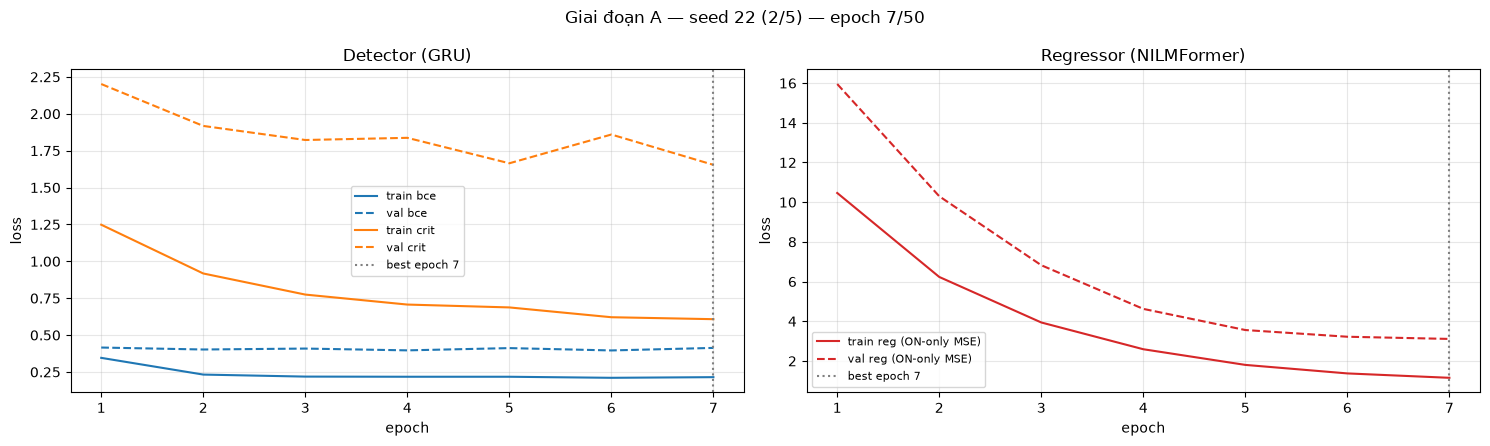

seed=22 epoch= 7 val reg=3.1108 bce=0.4132 crit=1.6539 score=5.1778 | best epoch 7


KeyboardInterrupt: 

In [30]:
select = {}
for seed in SEEDS:
    ck = train_seed(seed, train_ids, val_ids, EPOCHS, f"Giai đoạn A — seed {seed} ({SEEDS.index(seed) + 1}/{len(SEEDS)})")
    torch.save(ck, CKPT_DIR / f"select_seed_{seed}.pt")
    select[seed] = ck

best_epochs  = [select[s]["best_epoch"] for s in SEEDS]
FINAL_EPOCHS = int(np.median(best_epochs))
print("best epoch mỗi seed:", dict(zip(SEEDS, best_epochs)), "→ FINAL_EPOCHS =", FINAL_EPOCHS)

## 5. Giai đoạn B — train production trên toàn bộ dữ liệu trước test

Cùng cấu hình, số epoch cố định `FINAL_EPOCHS`; dùng thêm ~2,5 tháng (val) sát giai đoạn test.

In [ ]:
final = {}
for seed in SEEDS:
    ck = train_seed(seed, pool_ids, None, FINAL_EPOCHS, f"Giai đoạn B — seed {seed} ({SEEDS.index(seed) + 1}/{len(SEEDS)})")
    torch.save(ck, CKPT_DIR / f"final_seed_{seed}.pt")
    final[seed] = ck
print("đã train", len(final), "seed, mỗi seed", FINAL_EPOCHS, "epoch")

## 6. Ensemble và suy luận

`predict` là **toàn bộ logic suy luận** (app tái hiện đúng hàm này):
P(ON) = trung bình detector; công suất = trung vị regressor (×`scale_w`, ≥ 0); thiết bị = P(ON) × công suất; Other = tổng − thiết bị.

In [ ]:
def build_members(members: list[dict]):
    """members: list các dict {detector_config, regressor_config, detector_state, regressor_state, scale_w}."""
    detectors, regressors, scales = [], [], []
    for m in members:
        d = GRUDetector(GRUConfig(**m["detector_config"]));                 d.load_state_dict(m["detector_state"])
        r = NILMFormerRegressor(NILMFormerConfig(**m["regressor_config"])); r.load_state_dict(m["regressor_state"])
        detectors.append(d.to(DEVICE).eval()); regressors.append(r.to(DEVICE).eval())
        scales.append(torch.as_tensor(m["scale_w"], dtype=torch.float32, device=DEVICE))
    return detectors, regressors, torch.stack(scales)                       # scales: (M, C)


@torch.no_grad()
def predict(ensemble, xb: torch.Tensor, gate: str = "soft", event_thresholds=None):
    """xb: (B, 9, L) [aggregate W, time features] -> p_on, power_w, appliance_w (B, C, L), other_w (B, L)."""
    detectors, regressors, scales = ensemble
    z, xr = detector_inputs(xb), regressor_inputs(xb)
    p_on    = torch.stack([torch.sigmoid(d(z)) for d in detectors]).mean(0)
    power_w = torch.stack([r(xr) * s[None, :, None] for r, s in zip(regressors, scales)]).median(0).values.clamp(min=0)
    g = p_on if gate == "soft" else (p_on >= event_thresholds[None, :, None]).float()
    appliance_w = power_w * g
    other_w = (xb[:, 0] - appliance_w.sum(1)).clamp(min=0)
    return p_on, power_w, appliance_w, other_w


def run(ensemble, ids: np.ndarray, batch: int = 512, **kw) -> dict:
    outs = [predict(ensemble, torch.from_numpy(x[ids[i:i + batch]]).to(DEVICE), **kw) for i in range(0, len(ids), batch)]
    keys = ["p_on", "power_w", "appliance_w", "other_w"]
    return {k: torch.cat([o[j] for o in outs]).cpu().numpy() for j, k in enumerate(keys)}


ens_select = build_members([select[s] for s in SEEDS])     # giai đoạn A: chưa thấy val
ens_final  = build_members([final[s]  for s in SEEDS])     # giai đoạn B: production

## 7. Đánh giá

- Ngưỡng ON/OFF (chỉ cho hiển thị sự kiện "đang chạy" và F1; **năng lượng dùng mặt nạ mềm**) chỉnh trên val bằng ensemble giai đoạn A — sạch vì A chưa train trên val.
- Ensemble B đã train trên val nên **không** đánh giá được trên val.
- **Test chấm một lần** cho cả A và B.

In [ ]:
THRESHOLD_GRID = np.linspace(0.02, 0.98, 49)


def onoff_metrics(t: np.ndarray, p: np.ndarray) -> dict:
    tp, fp, fn = (t & p).sum(), (~t & p).sum(), (t & ~p).sum()
    prec, rec = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    return {"precision": prec, "recall": rec, "F1": 2 * prec * rec / max(prec + rec, 1e-12)}


def power_metrics(t: np.ndarray, p: np.ndarray) -> dict:
    t, p, err = t.ravel(), p.ravel(), (p - t).ravel()
    return {"MAE": np.abs(err).mean(),
            "NDE": (err ** 2).sum() / max((t ** 2).sum(), 1e-8),
            "SAE": abs(p.sum() - t.sum()) / max(t.sum(), 1e-8)}


def kwh(w: np.ndarray) -> np.ndarray:
    return w.sum(axis=(0, 2)) * SAMPLE_SECONDS / 3.6e6


def report(ensemble, ids: np.ndarray, event_thresholds: np.ndarray):
    out = run(ensemble, ids)
    pred_w, true_w, true_on = out["appliance_w"], y[ids], on[ids]
    pred_on = out["p_on"] >= event_thresholds[None, :, None]
    t_kwh, p_kwh = kwh(true_w), kwh(pred_w)
    table = pd.DataFrame({"true kWh": t_kwh, "pred kWh": p_kwh, "err %": 100 * (p_kwh - t_kwh) / t_kwh}, index=names)
    per = pd.DataFrame([power_metrics(true_w[:, c], pred_w[:, c]) | onoff_metrics(true_on[:, c], pred_on[:, c])
                        for c in range(len(names))], index=names)
    summary = {"mean |kWh err| %": table["err %"].abs().mean(),
               "total kWh err %": 100 * (p_kwh.sum() / t_kwh.sum() - 1),
               **per[["MAE", "NDE", "SAE", "F1"]].mean().to_dict()}
    return table, per, summary


p_on_val = run(ens_select, val_ids)["p_on"]
EVENT_THRESHOLDS = np.array([THRESHOLD_GRID[int(np.argmax([onoff_metrics(on[val_ids][:, c], p_on_val[:, c] >= t)["F1"]
                                                           for t in THRESHOLD_GRID]))] for c in range(len(names))],
                            dtype=np.float32)
print("ngưỡng sự kiện ON/OFF:", dict(zip(names, EVENT_THRESHOLDS.round(2))))

pd.set_option("display.width", 200)
val_table, _, val_summary = report(ens_select, val_ids, EVENT_THRESHOLDS)
print("\n=== VAL — ensemble A ===\n", val_table.round(1), "\n", pd.Series(val_summary).round(3).to_string())

In [ ]:
# TEST — chỉ chạy một lần, sau khi mọi lựa chọn đã cố định
results = {name: report(ens, test_ids, EVENT_THRESHOLDS) for name, ens in [("A (train)", ens_select), ("B (production)", ens_final)]}

print("=== TEST — kWh theo thiết bị ===")
print(pd.concat({k: v[0] for k, v in results.items()}, axis=1).round(1))
print("\n=== TEST — tóm tắt ===")
print(pd.DataFrame({k: v[2] for k, v in results.items()}).T.round(3))
print("\n=== TEST — chi tiết production ===")
print(results["B (production)"][1].round(3))

## 8. Export weights + config cho app

File chỉ chứa config (kiểu Python thuần) + tensor → load bằng `torch.load(weights_only=True)`; app dựng lại bằng `GRUDetector` / `NILMFormerRegressor` trong `model/` và tái hiện `predict` ở mục 6.

In [ ]:
BUNDLE_PATH = CKPT_DIR / "nilm_pipeline.pt"

bundle = {
    "format": "wattprint-nilm/2",
    "appliances": core_channels, "labels": names,
    "on_threshold_w": thresholds_w.tolist(),
    "gate": "soft",
    "event_thresholds": EVENT_THRESHOLDS.tolist(),          # chỉ cho hiển thị ON/OFF
    "tau_w": TAU_W, "sample_seconds": SAMPLE_SECONDS, "window": int(x.shape[-1]),
    "input": "(B, 9, L) float32: aggregate W (resample 15 s, clip [0, 10 kW]) + 8 sin/cos time features (data.py)",
    "output": "appliance W (B, C, L) = P(ON) x power; Other = aggregate - sum(appliances), clamp >= 0",
    "members": [{k: final[s][k] for k in ("seed", "scale_w", "detector_config", "regressor_config",
                                          "detector_state", "regressor_state")} for s in SEEDS],
    "meta": {"lambda": LAMBDA, "final_epochs": FINAL_EPOCHS, "seeds": SEEDS,
             "trained_until": str(window_start[pool_ids].max()),
             "test_summary": {k: float(v) for k, v in results["B (production)"][2].items()}},
}
torch.save(bundle, BUNDLE_PATH)

# Kiểm tra: load an toàn rồi dựng lại từ model/ phải ra đúng kết quả
loaded   = torch.load(BUNDLE_PATH, map_location="cpu", weights_only=True)
ens_back = build_members(loaded["members"])
xb = torch.from_numpy(x[test_ids[:64]]).to(DEVICE)
same = all(torch.allclose(a, b, atol=1e-4) for a, b in zip(predict(ens_final, xb), predict(ens_back, xb)))
assert same, "bundle load lại cho kết quả khác"
print(f"exported {BUNDLE_PATH} ({BUNDLE_PATH.stat().st_size / 1e6:.1f} MB), weights_only reload OK")